# Mappe della correzione geometrica del ToF

Origine: `~/juno/pos/test/graph2.ipynb`.

Copia organizzata per la consultazione: le celle eseguibili e gli output originali sono conservati. I titoli aggiunti sono celle Markdown; i risultati salvati non sono stati ricalcolati. Eseguire dalla cartella di questo notebook. I dati ROOT esterni e gli eventuali problemi già presenti sono descritti in `docs/DATI_E_PERCORSI.md` nella radice del repository.


## Librerie


In [1]:
import numpy as np
import uproot
import matplotlib.pyplot as plt

## Mappa della prima scansione in posizione


[-1.   -0.95 -0.9  -0.85 -0.8  -0.75 -0.7  -0.65 -0.6  -0.55 -0.5  -0.45
 -0.4  -0.35 -0.3  -0.25 -0.2  -0.15 -0.1  -0.05  0.    0.05  0.1   0.15
  0.2   0.25  0.3   0.35  0.4   0.45  0.5   0.55  0.6   0.65  0.7   0.75
  0.8   0.85  0.9   0.95  1.  ]


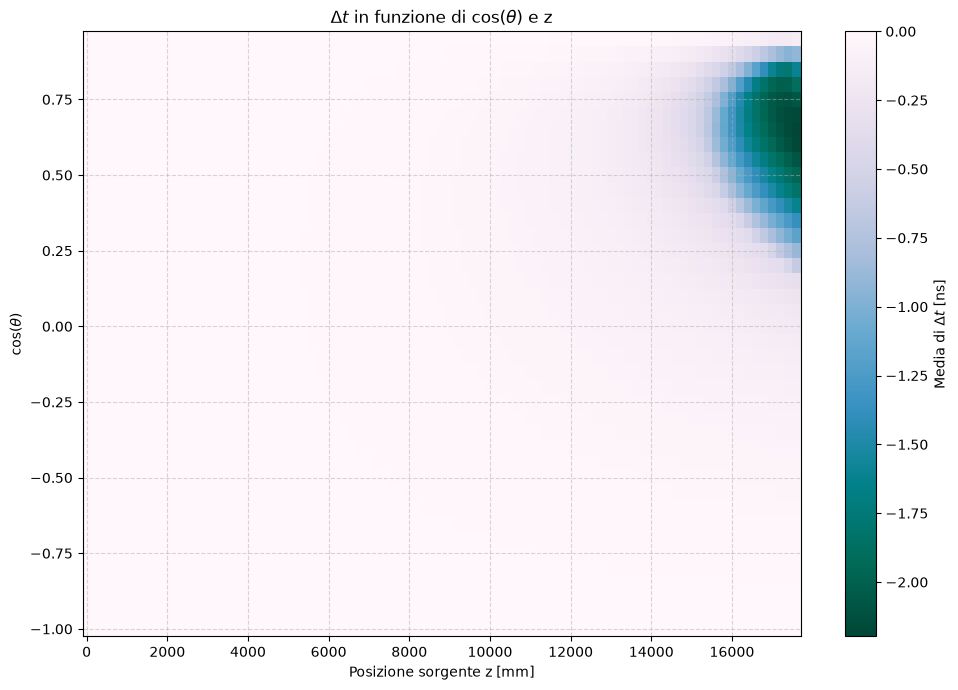

In [4]:
with uproot.open("output3.root") as file:
    tree = file["tof_cal"]
    data = tree.arrays(library= "np")

# Ora io devo prendere la media di delta tra i pmt con un certo cos_theta
a= np.linspace(-1, 1 ,41)

z_source = np.loadtxt("pos_z2.txt")
print(a)

delta_mean= np.full(shape=(len(a)-1, len(z_source)), fill_value=np.nan)


for j,z  in enumerate(z_source):
    for i in range(len(a)-1):
        mask = (data["cos_theta"] >= a[i]) & (data["cos_theta"] < a[i+1]) & (data["posZ"]==z)
        delta_mean[i, j] = np.mean(data["delta_ns"][mask])

fig, ax = plt.subplots(figsize=(10, 7))

plot = ax.pcolormesh(
    z_source,
    a[:-1],
    delta_mean,
    shading="auto",
    cmap="PuBuGn_r"
)

cbar = fig.colorbar(plot, ax=ax)
cbar.set_label(r"Media di $\Delta t$ [ns]")

ax.set_xlabel("Posizione sorgente z [mm]")
ax.set_ylabel(r"$\cos(\theta)$")
ax.set_title(r"$\Delta t$ in funzione di $\cos(\theta)$ e z")
ax.grid(linestyle="--", alpha= 0.5)

plt.tight_layout()
plt.show()


## Generazione della griglia delle posizioni


In [27]:
b = np.arange(0, 17700, 200)
np.savetxt("pos_z2.txt", b)

## Mappa della seconda scansione


[-1.   -0.96 -0.92 -0.88 -0.84 -0.8  -0.76 -0.72 -0.68 -0.64 -0.6  -0.56
 -0.52 -0.48 -0.44 -0.4  -0.36 -0.32 -0.28 -0.24 -0.2  -0.16 -0.12 -0.08
 -0.04  0.    0.04  0.08  0.12  0.16  0.2   0.24  0.28  0.32  0.36  0.4
  0.44  0.48  0.52  0.56  0.6   0.64  0.68  0.72  0.76  0.8   0.84  0.88
  0.92  0.96  1.  ]


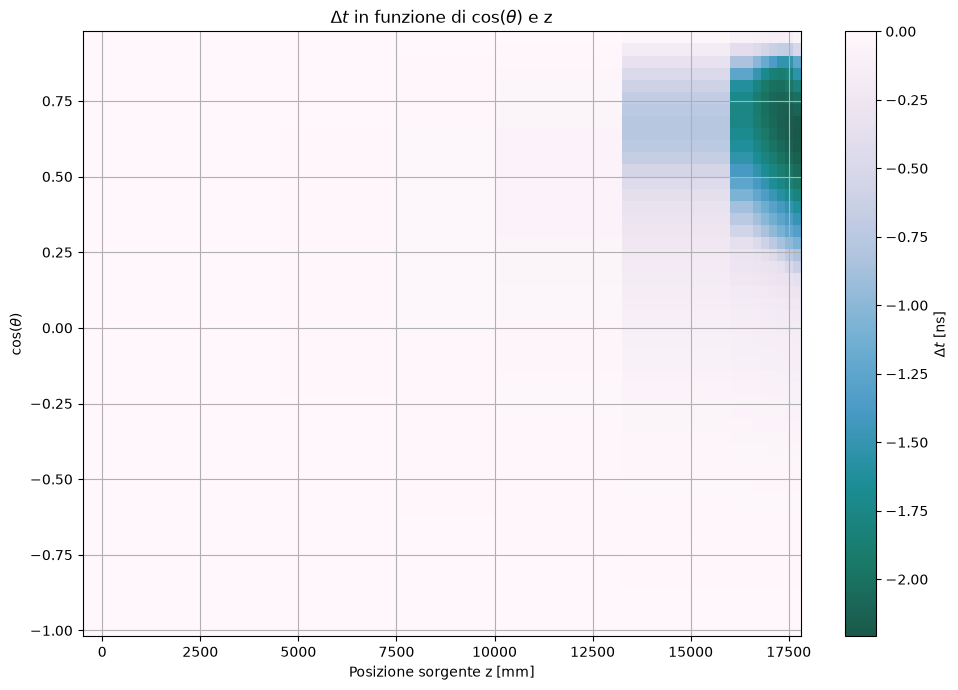

In [5]:
with uproot.open("output2.root") as file:
    tree = file["tof_cal"]
    data = tree.arrays(library= "np")

# Ora io devo prendere la media di delta tra i pmt con un certo cos_theta
a= np.linspace(-1, 1 ,51)

z_source = np.loadtxt("pos_z.txt")
print(a)

delta_mean= np.full(shape=(len(a)-1, len(z_source)), fill_value=np.nan)


for j,z  in enumerate(z_source):
    for i in range(len(a)-1):
        mask = (data["cos_theta"] >= a[i]) & (data["cos_theta"] < a[i+1]) & (data["posZ"]==z)
        delta_mean[i, j] = np.mean(data["delta_ns"][mask])

fig, ax = plt.subplots(figsize=(10, 7))

plot = ax.pcolormesh(
    z_source,
    a[:-1],
    delta_mean,
    shading="auto",
    cmap="PuBuGn_r",
    alpha = 0.9
)

cbar = fig.colorbar(plot, ax=ax)
cbar.set_label(r"$\Delta t$ [ns]")

ax.set_xlabel("Posizione sorgente z [mm]")
ax.set_ylabel(r"$\cos(\theta)$")
ax.set_title(r"$\Delta t$ in funzione di $\cos(\theta)$ e z")
ax.grid()   
plt.tight_layout()
plt.show()


### Mappa correttiva: bin con derivata non nulla
La derivata è quella del cammino ottico rispetto all’angolo di uscita, valutata nel minimo trovato da `Pmt::tof_true2`. Si usa direttamente `Pmt::check_theta` in `pmt.h`: la condizione di annullamento numerico è $|dL/d\theta| < 0.1$ (mm/rad). Un bin è rosso se contiene **almeno un PMT** che non soddisfa questa condizione; non si media la derivata, così segni opposti non si cancellano. I bin vuoti restano bianchi.

Le mappe precedenti restano invariate. La cella è autonoma e usa `output5.root`, verificato coerente con il `pmt.h` attuale, sulla stessa griglia della prima mappa. `output3.root` differisce dal ricalcolo fino a circa 0,063 ns; `root_path` permette di scegliere un altro ROOT. Richiede `g++`, NumPy, uproot e Matplotlib. Ricalcola con i parametri di `main.cpp`, verifica la compatibilità con i Δt salvati e compila solo in una cartella temporanea. Non esegue la cella precedente che riscrive `pos_z2.txt`. Un minimo vincolato al bordo può avere derivata non nulla: il rosso è un criterio diagnostico, non prova da solo un errore.


**Versione per presentazione:** nella fascia $\cos(\theta)>0.96$, i PMT inizialmente fuori soglia vengono ricontrollati con tolleranza angolare $10^{-10}$ rad. Il rosso mostra solo gli esiti ancora fuori soglia dopo questo controllo; la mappa di Δt resta quella del ROOT. Il grafico è esportato anche in PNG a 300 dpi.


output5.root: 151 / 4450 bin occupati in rosso; 50762 / 1567468 coppie (z, PMT) fuori soglia.


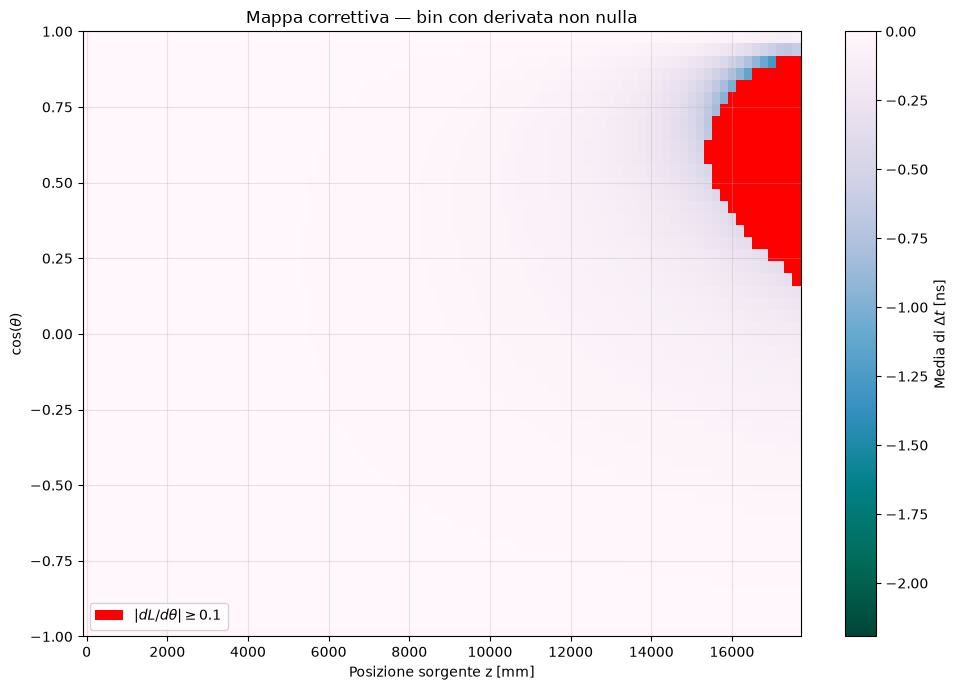

In [1]:
from pathlib import Path
import subprocess
import tempfile
import numpy as np
import uproot
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

# output5.root riproduce il pmt.h attuale (output3.root usa una versione precedente).
# Stessa griglia della prima mappa; output4.root contiene la scansione meno fitta.
root_path = Path('output5.root').resolve()
base_dir = root_path.parent
# Parametri di main.cpp; check_theta in pmt.h usa |derivata| < 0.1.
n_s, n_w, errore_theta = 1.54, 1.33, 1e-6
# Lettura locale sincrona per evitare blocchi di fsspec con Python 3.14.
with uproot.open(root_path, handler=uproot.source.file.MultithreadedFileSource,
                 decompression_executor=uproot.source.futures.TrivialExecutor(),
                 interpretation_executor=uproot.source.futures.TrivialExecutor()) as root_file:
    dati_der = root_file['tof_cal'].arrays(library='np')
z_der = np.unique(dati_der['posZ'])

# Richiama il Pmt originale: nessuna modifica a main.cpp o pmt.h.
# Il temporaneo contiene un esito per ogni coppia (z, PMT), insieme a Delta t
# per verificare che il codice attuale riproduca la mappa salvata nel ROOT.
cpp = r'''
#include <fstream>
#include <iomanip>
#include <vector>
#include "pmt.h"
int main(int argc, char** argv) {
    std::ifstream positions(argv[1]), sources(argv[2]);
    std::ofstream output(argv[3], std::ios::binary);
    if (!positions || !sources || !output) return 1;
    std::vector<Pmt> pmts;
    int id; double x,y,z; std::string type;
    while (positions >> id >> x >> y >> z >> type)
        pmts.emplace_back(id,x,y,z,type);
    if (pmts.empty()) return 2;
    const double ns=std::stod(argv[4]), nw=std::stod(argv[5]);
    const double error=std::stod(argv[6]);
    // check_theta stampa ogni fallimento su stderr: qui salviamo gli esiti.
    std::cerr.setstate(std::ios_base::failbit);
    while (sources >> z) {
        for (auto& p : pmts) {
            p.initialize(0.,0.,z,ns,nw,error);
            const double delta = p.get_time_true()-p.get_time();
            bool stationary = p.check_theta(z,ns,nw);
            // Nella fascia polare i falsi positivi dipendono dalla tolleranza:
            // ricontrolla a 1e-10 rad prima di evidenziare il PMT.
            if (!stationary && p.get_cos_theta() > 0.96) {
                p.initialize(0.,0.,z,ns,nw,1e-10);
                stationary = p.check_theta(z,ns,nw);
            }
            double row[4] = {z, double(std::abs(p.get_index())),
                double(stationary), delta};
            output.write(reinterpret_cast<const char*>(row), sizeof(row));
        }
    }
    return output.good() ? 0 : 3;
}
'''
with tempfile.TemporaryDirectory(prefix='mappa_derivata_') as tmp:
    tmp = Path(tmp)
    (tmp / 'check.cpp').write_text(cpp)
    np.savetxt(tmp / 'z.txt', z_der, fmt='%.17g')
    subprocess.run(['g++', '-O2', '-std=c++11', '-I', str(base_dir),
                    str(tmp / 'check.cpp'), '-o', str(tmp / 'check')], check=True)
    subprocess.run([str(tmp / 'check'), str(base_dir / 'pmt_positions.csv'),
                    str(tmp / 'z.txt'), str(tmp / 'result.bin'),
                    str(n_s), str(n_w), str(errore_theta)], check=True)
    risultati = np.fromfile(tmp / 'result.bin', dtype=np.float64).reshape(-1, 4)

# Allineamento esplicito per z e ID, indipendente dall'ordine nel ROOT/CSV.
ids_der = np.unique(risultati[:, 1]).astype(np.int64)
iz_r = np.searchsorted(z_der, risultati[:, 0])
ip_r = np.searchsorted(ids_der, risultati[:, 1])
chiavi_r = iz_r * len(ids_der) + ip_r
if len(np.unique(chiavi_r)) != len(z_der) * len(ids_der):
    raise ValueError('Coppie (z, PMT) mancanti o duplicate nel ricalcolo.')
ordine_r = np.argsort(chiavi_r)
ip_d = np.searchsorted(ids_der, dati_der['pmt_id'])
if np.any(ip_d >= len(ids_der)) or not np.array_equal(ids_der[ip_d], dati_der['pmt_id']):
    raise ValueError('Il ROOT contiene ID assenti dalle posizioni PMT.')
iz_d = np.searchsorted(z_der, dati_der['posZ'])
righe = ordine_r[iz_d * len(ids_der) + ip_d]
if not np.allclose(risultati[righe, 3], dati_der['delta_ns'], rtol=1e-7, atol=1e-5):
    raise ValueError('Il ROOT non coincide con pmt.h e i parametri attuali: '
                     'rigenerare il ROOT con main.cpp prima di sovrapporre gli esiti.')
non_nulla = risultati[righe, 2] == 0

# 50 bin in cos(theta), stessi intervalli della mappa correttiva.
cos_edges = np.linspace(-1, 1, 51)
ic = np.searchsorted(cos_edges, dati_der['cos_theta'], side='right') - 1
ic[dati_der['cos_theta'] == 1] = len(cos_edges) - 2
validi = (ic >= 0) & (ic < 50) & np.isfinite(dati_der['delta_ns'])
shape = (50, len(z_der))
conteggi = np.zeros(shape, dtype=int)
conteggi_non_nulli = np.zeros(shape, dtype=int)
somme = np.zeros(shape)
np.add.at(conteggi, (ic[validi], iz_d[validi]), 1)
np.add.at(somme, (ic[validi], iz_d[validi]), dati_der['delta_ns'][validi])
np.add.at(conteggi_non_nulli, (ic[validi], iz_d[validi]), non_nulla[validi])
media_der = np.divide(somme, conteggi, out=np.full(shape, np.nan), where=conteggi > 0)
bin_rossi = conteggi_non_nulli > 0
# Bordi z espliciti: i campioni sono i centri dei bin.
if len(z_der) < 2:
    z_edges = np.array([z_der[0] - 0.5, z_der[0] + 0.5])
else:
    z_edges = np.r_[z_der[0] - (z_der[1]-z_der[0])/2,
                    (z_der[:-1]+z_der[1:])/2,
                    z_der[-1] + (z_der[-1]-z_der[-2])/2]
fig, ax = plt.subplots(figsize=(10, 7))
plot = ax.pcolormesh(z_edges, cos_edges, media_der, shading='flat', cmap='PuBuGn_r')
fig.colorbar(plot, ax=ax, label=r'Media di $\Delta t$ [ns]')
ax.pcolormesh(z_edges, cos_edges, np.ma.masked_where(~bin_rossi, np.ones(shape)),
              shading='flat', cmap=ListedColormap(['red']), vmin=0, vmax=1)
ax.set(xlabel='Posizione sorgente z [mm]', ylabel=r'$\cos(\theta)$',
       title='Mappa correttiva — bin con derivata non nulla')
ax.legend(handles=[Patch(facecolor='red', label=r'$|dL/d\theta|\geq 0.1$')],
          loc='lower left')
ax.grid(alpha=0.3)
fig.tight_layout()
print(f'{root_path.name}: {bin_rossi.sum()} / {(conteggi > 0).sum()} bin occupati in rosso; '
      f'{non_nulla[validi].sum()} / {validi.sum()} coppie (z, PMT) fuori soglia.')
fig.savefig(base_dir / 'mappa_correttiva_presentazione.png', dpi=300, bbox_inches='tight')
plt.show()
